#### Подготовка данных

Импорт библиотек

In [41]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style='whitegrid')

Загрузка данных

In [42]:
events = pd.read_excel('NHL-playoffs-2026.xlsx', index_col=0)

In [43]:
events.shape

(29710, 38)

Все данные

In [44]:
events.head()

,Dataset,Game ID,Date,Away Team,Home Team,Cumulated Away Score,Cumulated Home Score,Period,Elapsed Time,Remaining Time,...,Away Team's Player on the Ice #6,Away Team's Goalie,Home Team's Player on the Ice #1,Home Team's Player on the Ice #2,Home Team's Player on the Ice #3,Home Team's Player on the Ice #4,Home Team's Player on the Ice #5,Home Team's Player on the Ice #6,Home Team's Goalie,Home Team's Defending Side
0,NHL 2026 playoffs,2025030111,2026-04-19,Boston Bruins,Buffalo Sabres,0,0,1,00:00,20:00,...,Pavel Zacha,Jeremy Swayman,Rasmus Dahlin,Peyton Krebs,Ukko-Pekka Luukkonen,Mattias Samuelsson,Tage Thompson,Alex Tuch,Ukko-Pekka Luukkonen,left
1,NHL 2026 playoffs,2025030111,2026-04-19,Boston Bruins,Buffalo Sabres,0,0,1,00:00,20:00,...,Pavel Zacha,Jeremy Swayman,Rasmus Dahlin,Peyton Krebs,Ukko-Pekka Luukkonen,Mattias Samuelsson,Tage Thompson,Alex Tuch,Ukko-Pekka Luukkonen,left
2,NHL 2026 playoffs,2025030111,2026-04-19,Boston Bruins,Buffalo Sabres,0,0,1,00:13,19:47,...,Pavel Zacha,Jeremy Swayman,Rasmus Dahlin,Peyton Krebs,Ukko-Pekka Luukkonen,Mattias Samuelsson,Tage Thompson,Alex Tuch,Ukko-Pekka Luukkonen,left
3,NHL 2026 playoffs,2025030111,2026-04-19,Boston Bruins,Buffalo Sabres,0,0,1,00:14,19:46,...,Pavel Zacha,Jeremy Swayman,Rasmus Dahlin,Peyton Krebs,Ukko-Pekka Luukkonen,Mattias Samuelsson,Tage Thompson,Alex Tuch,Ukko-Pekka Luukkonen,left
4,NHL 2026 playoffs,2025030111,2026-04-19,Boston Bruins,Buffalo Sabres,0,0,1,00:19,19:41,...,Pavel Zacha,Jeremy Swayman,Rasmus Dahlin,Peyton Krebs,Ukko-Pekka Luukkonen,Mattias Samuelsson,Tage Thompson,Alex Tuch,Ukko-Pekka Luukkonen,left


In [45]:
events.iloc[:10,[2,3,4,9,12]]

,Date,Away Team,Home Team,Remaining Time,Play Type
0,2026-04-19,Boston Bruins,Buffalo Sabres,20:00,period-start
1,2026-04-19,Boston Bruins,Buffalo Sabres,20:00,faceoff
2,2026-04-19,Boston Bruins,Buffalo Sabres,19:47,hit
3,2026-04-19,Boston Bruins,Buffalo Sabres,19:46,hit
4,2026-04-19,Boston Bruins,Buffalo Sabres,19:41,hit
5,2026-04-19,Boston Bruins,Buffalo Sabres,19:27,hit
6,2026-04-19,Boston Bruins,Buffalo Sabres,19:03,hit
7,2026-04-19,Boston Bruins,Buffalo Sabres,18:53,missed-shot
8,2026-04-19,Boston Bruins,Buffalo Sabres,18:48,hit
9,2026-04-19,Boston Bruins,Buffalo Sabres,18:37,missed-shot


`Полезные` данные

In [46]:
cols = ['Date', 'Away Team', 'Home Team', 'Remaining Time', 'Play Type']

events[cols].head(10)

,Date,Away Team,Home Team,Remaining Time,Play Type
0,2026-04-19,Boston Bruins,Buffalo Sabres,20:00,period-start
1,2026-04-19,Boston Bruins,Buffalo Sabres,20:00,faceoff
2,2026-04-19,Boston Bruins,Buffalo Sabres,19:47,hit
3,2026-04-19,Boston Bruins,Buffalo Sabres,19:46,hit
4,2026-04-19,Boston Bruins,Buffalo Sabres,19:41,hit
5,2026-04-19,Boston Bruins,Buffalo Sabres,19:27,hit
6,2026-04-19,Boston Bruins,Buffalo Sabres,19:03,hit
7,2026-04-19,Boston Bruins,Buffalo Sabres,18:53,missed-shot
8,2026-04-19,Boston Bruins,Buffalo Sabres,18:48,hit
9,2026-04-19,Boston Bruins,Buffalo Sabres,18:37,missed-shot


#### 2 Сводная информация об играх

In [47]:
games = events.groupby('Game ID').agg({
    'Date': 'first',
    'Away Team': 'first',
    'Home Team': 'first',
    'Cumulated Away Score': 'last',
    'Cumulated Home Score': 'last',
    'Period': 'max'
})

games = games.rename(columns={
    'Cumulated Away Score': 'Away Score',
    'Cumulated Home Score': 'Home Score'
})

games['Outcome'] = 'Final'

# С овертаймами
games.loc[games['Period'] > 3, 'Outcome'] = (
    'Final/' + (games.loc[games['Period'] > 3, 'Period'] - 3).astype(str) + 'OT'
)

# Один овертайм записываем как Final/OT
games['Outcome'] = games['Outcome'].replace('Final/1OT', 'Final/OT')

games = games.drop(columns='Period')

In [48]:
games.tail()

,Date,Away Team,Home Team,Away Score,Home Score,Outcome
Game ID,,,,,,
2025030412,2026-06-04,Vegas Golden Knights,Carolina Hurricanes,3,4,Final/OT
2025030413,2026-06-06,Carolina Hurricanes,Vegas Golden Knights,4,5,Final/2OT
2025030414,2026-06-09,Carolina Hurricanes,Vegas Golden Knights,5,3,Final
2025030415,2026-06-11,Vegas Golden Knights,Carolina Hurricanes,2,4,Final
2025030416,2026-06-14,Carolina Hurricanes,Vegas Golden Knights,3,0,Final


#### 3 функция GameInfo

In [49]:
def gameInfo(gameId):
    game = games.loc[gameId]
    return (f"{game['Home Team']} - {game['Away Team']} "
            f"({game['Home Score']} - {game['Away Score']}, "
            f"{game['Outcome']}, {game['Date']})")

In [50]:
print(gameInfo(games.index.min()))
print(gameInfo(games.index.max()))

Buffalo Sabres - Boston Bruins (4 - 3, Final, 2026-04-19)
Vegas Golden Knights - Carolina Hurricanes (0 - 3, Final, 2026-06-14)


#### 4-5 Забитые шайбы и статистика по **ним**

In [51]:
games['Total Score'] = games['Away Score'] + games['Home Score']

In [52]:
games['Total Score'].describe()

,Total Score
count,82.000000
mean,5.926829
std,2.259578
min,1.000000
25%,5.000000
50%,6.000000
75%,7.000000
max,15.000000


Гистограмма забитых шайб

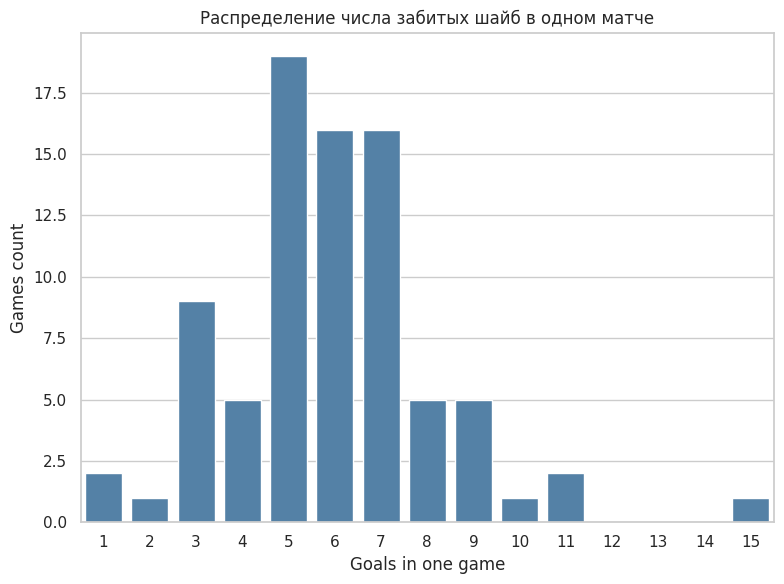

In [53]:
plt.figure(figsize=(8, 6))

sns.countplot(data=games, x='Total Score', order=range(1, 16), color='steelblue')
plt.xlabel('Goals in one game')
plt.ylabel('Games count')
plt.title('Распределение числа забитых шайб в одном матче')
plt.tight_layout()
plt.show()

* По гистограмме видно, что чаще всего в матчах забивали от `5` до `7` голов, причём наиболее распространённый результат - `5` голов за матч. Среднее количество голов составляет примерно `5.9`. Матчи с очень низкой результативностью (1–2 гола) встречались редко, как и матчи с большим количеством голов (10 и более).         
* Самым результативным стал матч с `15` голами, что выделяется на фоне остальных.

In [54]:
games[games['Total Score'] == 15]

,Date,Away Team,Home Team,Away Score,Home Score,Outcome,Total Score
Game ID,,,,,,,
2025030231,2026-05-03,Minnesota Wild,Colorado Avalanche,6,9,Final,15


#### 6 Самые результативные и нерезультативные игры

In [55]:
low_games = games[games['Total Score'] == games['Total Score'].min()]
high_games = games[games['Total Score'] == games['Total Score'].max()]

print('Самые нерезультативные:')
for game_id in low_games.index:
    print(gameInfo(game_id))

print('\nСамые результативные:')
for game_id in high_games.index:
    print(gameInfo(game_id))

Самые нерезультативные:
Montréal Canadiens - Tampa Bay Lightning (0 - 1, Final/OT, 2026-05-01)
Philadelphia Flyers - Pittsburgh Penguins (1 - 0, Final/OT, 2026-04-29)

Самые результативные:
Colorado Avalanche - Minnesota Wild (9 - 6, Final, 2026-05-03)


Два матча закончились со счётом 1:0 (оба - в овертайме). Рекордный по результативности матч - `Colorado Avalanche - Minnesota Wild`, **9:6**

#### 7 Число игроков в матче

In [56]:
# Выбираем столбцы с игроками и вратарями
player_columns = [col for col in events.columns if 'Player on the Ice #' in col or 'Goalie' in col]

# Отдельно выделяем игроков гостей и хозяев
away_cols = [col for col in player_columns if 'Away Team' in col]
home_cols = [col for col in player_columns if 'Home Team' in col]

# Создаём словарь для хранения количества игроков в каждом матче
player_count = {}

# Перебираем все матчи
for game_id, game in events.groupby('Game ID'):
    away_players = set()
    home_players = set()

    # Создаём множества для уникальных игроков каждой команды
    for col in away_cols:
        away_players.update(game[col].dropna())

    # Собираем всех игроков гостей, убирая пропуски
    for col in home_cols:
        home_players.update(game[col].dropna())

    # Считаем общее количество уникальных игроков обеих команд
    player_count[game_id] = len(away_players) + len(home_players)

player_count = pd.Series(player_count)

# Находим максимальное количество игроков в одном матче
max_players = player_count.max()

# Выбираем матчи с максимальным количеством игроков
result_players = player_count[player_count == max_players].to_frame('Player Count')

# Добавляем информацию о найденных матчах
result_players.index.name = 'Game ID'
result_players['Game Info'] = result_players.index.map(gameInfo)


result_players[['Game Info', 'Player Count']]

,Game Info,Player Count
Game ID,,
2025030216,"Montréal Canadiens - Buffalo Sabres (3 - 8, Fi...",40


#### 8 Расстояние от шайбы до ворот

In [57]:
# Выбираем все незаблокированные броски
shots = events[events['Play Type'].isin(['shot-on-goal', 'goal', 'missed-shot'])].copy()


# Проверяем, бросают ли хозяева и защищают ли они левые ворота
is_home = shots['Team Making the Play'] == shots['Home Team']
defends_left = shots["Home Team's Defending Side"] == 'left'


shots['Goal X'] = np.where(is_home == defends_left, 89, -89)

# Получаем координаты бросков
x = shots['X Coordinate on the Ice Rink']
y = shots['Y Coordinate on the Ice Rink']

# Считаем расстояние до ближайшей точки створа ворот
shots['Shot Length'] = np.sqrt(
    (x - shots['Goal X'])**2 + (y.abs() - 3).clip(lower=0)**2
)

print(f'Всего незаблокированных бросков {len(shots)}')
shots[['Game ID', 'Play Type', 'Shot Length']].round(3).head(10)

Всего незаблокированных бросков 7266


,Game ID,Play Type,Shot Length
7,2025030111,missed-shot,12.207
9,2025030111,missed-shot,12.000
12,2025030111,missed-shot,29.411
13,2025030111,shot-on-goal,62.169
19,2025030111,missed-shot,52.924
23,2025030111,shot-on-goal,41.146
24,2025030111,shot-on-goal,2.236
28,2025030111,missed-shot,38.601
37,2025030111,missed-shot,58.310
43,2025030111,missed-shot,41.773


#### 9 Длины точных и неточных бросков

,count,mean,median
Shot,,,
Missed,2643,34.01,32.25
On goal,4623,36.21,31.83


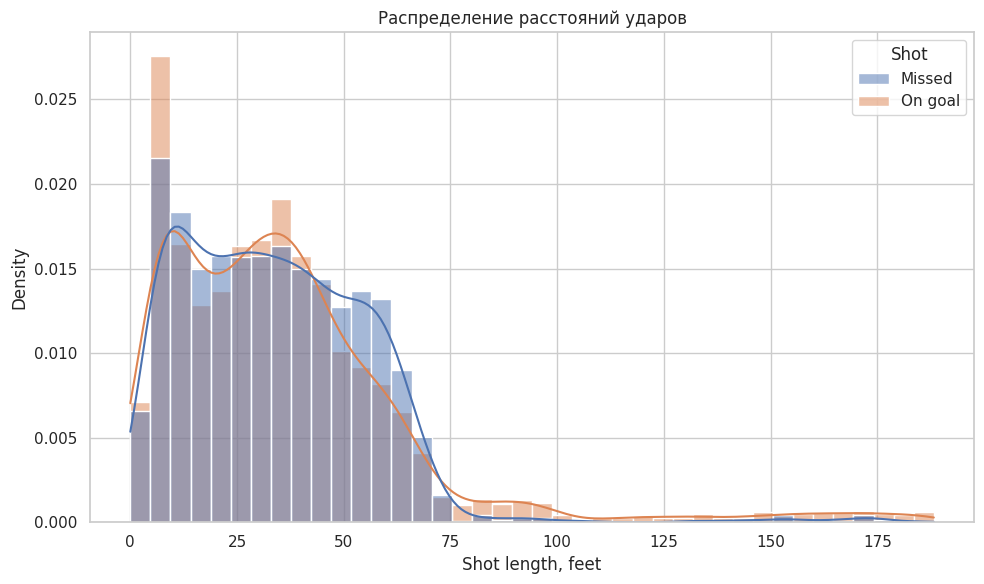

In [58]:
# Разделяем броски на точные и неточные
shots['Shot'] = 'On goal'
shots.loc[shots['Play Type'] == 'missed-shot', 'Shot'] = 'Missed'

# Сравниваем количество бросков и расстояния до ворот
display(shots.groupby('Shot')['Shot Length'].agg(['count', 'mean', 'median']).round(2))


plt.figure(figsize=(10, 6))

sns.histplot(
    data=shots, x='Shot Length', hue='Shot',
    stat='density', common_norm=False,
    multiple='layer', kde=True,
    bins=40, alpha=0.5
)

plt.xlabel('Shot length, feet')
plt.ylabel('Density')
plt.title('Распределение расстояний ударов')
plt.tight_layout()
plt.show()

* По гистограмме видно, что распределения точных и неточных бросков достаточно похожи. Большинство бросков совершается с расстояния до 75 футов. При этом на небольших дистанциях точные броски встречаются относительно чаще, а на больших расстояниях возрастает доля неточных бросков. Это объясняется тем, что с увеличением расстояния попасть в створ ворот становится сложнее.
* Длинный правый хвост распределения точных бросков может объясняться бросками по пустым воротам. Когда проигрывающая команда заменяет вратаря дополнительным полевым игроком, соперники получают возможность бросать в пустые ворота.

#### 10 Доля точных бросков у каждой команды

In [59]:
# Считаем точные и неточные броски каждой команды в каждом матче
numshots = shots.groupby(['Game ID', 'Team Making the Play', 'Shot']).size().unstack(fill_value=0)

# Считаем долю точных бросков
numshots['Share of Shots on Goal'] = numshots['On goal'] / (numshots['On goal'] + numshots['Missed'])

# Выводим результат

print(f'Средняя доля точных бросков {round(numshots['Share of Shots on Goal'].mean(), 3)}')

numshots['Share of Shots on Goal'].round(3)

Средняя доля точных бросков 0.639


Game ID     Team Making the Play
2025030111  Boston Bruins           0.625
            Buffalo Sabres          0.679
2025030112  Boston Bruins           0.614
            Buffalo Sabres          0.636
2025030113  Boston Bruins           0.694
                                    ...  
2025030414  Vegas Golden Knights    0.583
2025030415  Carolina Hurricanes     0.558
            Vegas Golden Knights    0.510
2025030416  Carolina Hurricanes     0.639
            Vegas Golden Knights    0.595
Name: Share of Shots on Goal, Length: 164, dtype: float64

В среднем около 64% всех незаблокированных бросков достигают створа ворот, то есть примерно каждый третий бросок проходит мимо. При этом доля точных бросков заметно различается как между командами, так и между отдельными матчами одной команды.

#### 11 Пять лучших и худших команд по доле точных бросков

In [60]:
avgnumshots = numshots.groupby(level='Team Making the Play')['Share of Shots on Goal'].mean()

print('Пять самых высоких долей')
display(avgnumshots.nlargest(5).round(3))
print('\n\n\n\nПять самых низких долей')
display(avgnumshots.nsmallest(5).round(3))

Пять самых высоких долей


,Share of Shots on Goal
Team Making the Play,
Edmonton Oilers,0.706
Philadelphia Flyers,0.684
Dallas Stars,0.670
Minnesota Wild,0.656
Colorado Avalanche,0.653






Пять самых низких долей


,Share of Shots on Goal
Team Making the Play,
Pittsburgh Penguins,0.554
Utah Mammoth,0.599
Carolina Hurricanes,0.615
Tampa Bay Lightning,0.626
Buffalo Sabres,0.626


Наибольшая средняя доля точных бросков у `Edmonton Oilers` - около **70,6%**, наименьшая у `Pittsburgh Penguins` - около **55,4%**. Однако эта доля сама по себе не говорит о качестве атак: у команд могут различаться дистанции бросков, количество матчей и доля забитых шайб, а не тех, что попали в створ ворот

#### 12 Средние числа бросков в створ и голов за игру

In [61]:
# Среднее количество бросков в створ за матч
avgshots = numshots.groupby('Team Making the Play')[['On goal']].mean()

# Среднее количество голов за матч
goals = shots[shots['Play Type'] == 'goal'].groupby('Team Making the Play').size()
games_count = numshots.groupby('Team Making the Play').size()

avgshots['Goal'] = (goals / games_count).fillna(0)

# Переименовываем столбец
avgshots = avgshots.rename(columns={'On goal': 'Shot'})

avgshots.round(3)

Shot,Shot,Goal
Team Making the Play,,
Anaheim Ducks,31.667,3.250
Boston Bruins,25.167,2.000
Buffalo Sabres,30.462,3.308
Carolina Hurricanes,31.632,3.474
Colorado Avalanche,32.154,3.385
Dallas Stars,31.000,2.500
Edmonton Oilers,28.333,3.500
Los Angeles Kings,25.250,1.250
Minnesota Wild,28.727,3.727


#### 13 Регрессия

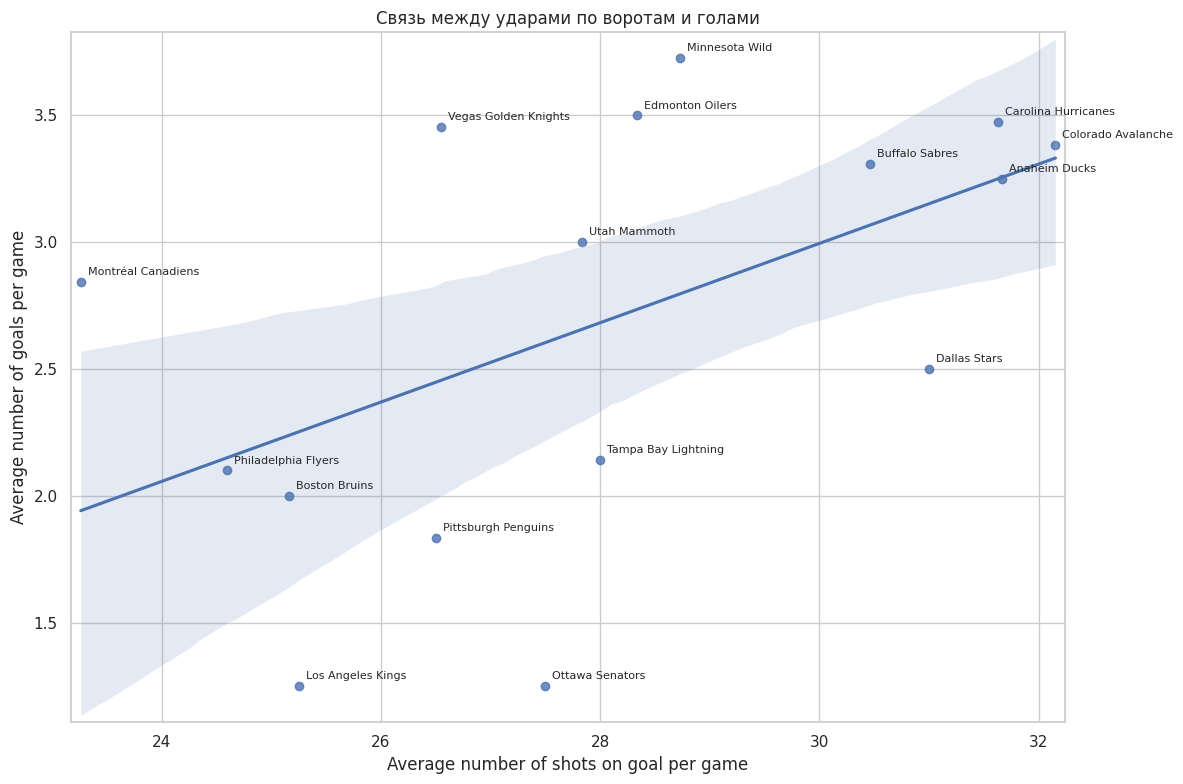

Корреляция 0.521


In [62]:
# Строим регрессионную диаграмму
plt.figure(figsize=(12, 8))

sns.regplot(data=avgshots, x='Shot', y='Goal')

# Подписываем каждую команду рядом с её точкой
for team, row in avgshots.iterrows():
    plt.annotate(
        team,
        (row['Shot'], row['Goal']),
        xytext=(5, 5),
        textcoords='offset points',
        fontsize=8
    )

plt.xlabel('Average number of shots on goal per game')
plt.ylabel('Average number of goals per game')
plt.title('Связь между ударами по воротам и голами')
plt.margins(x=0.01, y=0.01)
plt.tight_layout()
plt.show()

# Считаем корреляцию
print(f'Корреляция {round(avgshots['Shot'].corr(avgshots['Goal']), 3)}')

Без названий команд

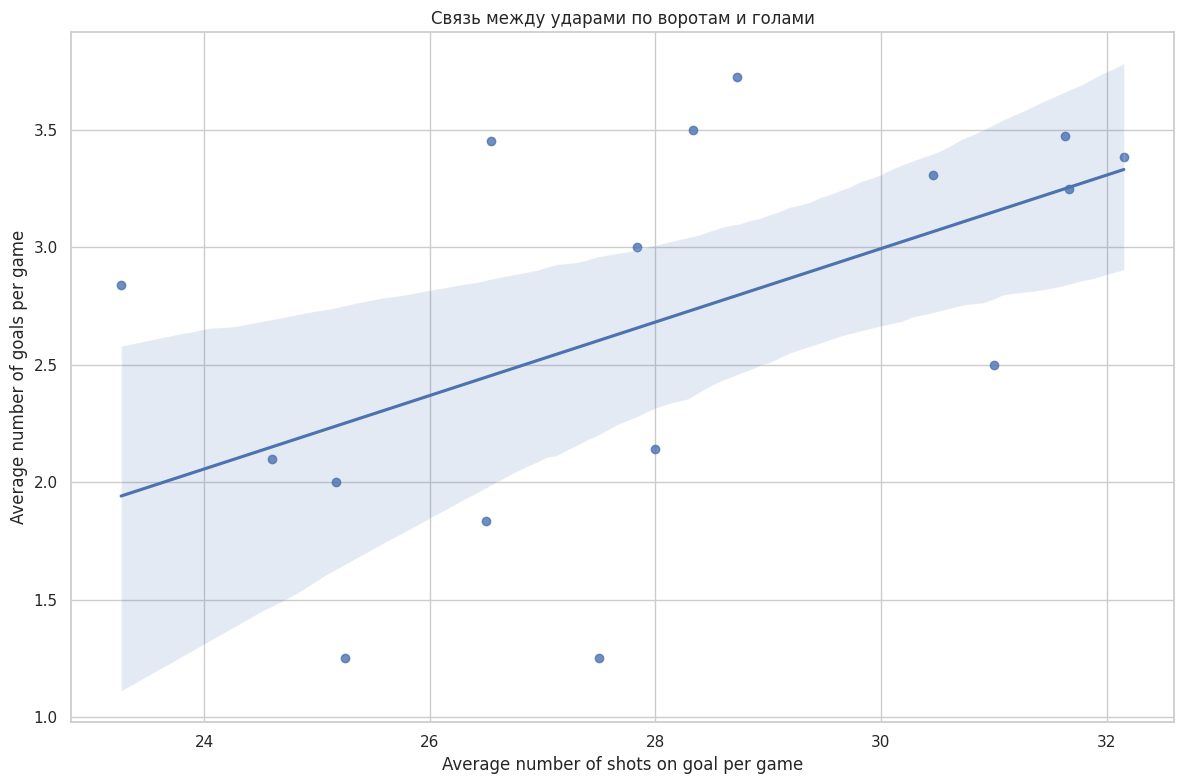

In [63]:
# Строим регрессионную диаграмму
plt.figure(figsize=(12, 8))

sns.regplot(data=avgshots, x='Shot', y='Goal')

plt.xlabel('Average number of shots on goal per game')
plt.ylabel('Average number of goals per game')
plt.title('Связь между ударами по воротам и голами')
plt.tight_layout()
plt.show()

На диаграмме положительная связь между средним количеством бросков в створ ворот и средним количеством голов за матч. В целом команды, которые чаще бросают в створ, забивают больше голов. Однако точки достаточно сильно разбросаны относительно линии. **Поэтому можно сказать, что связь есть, но она умеренная**

#### 14 Максимальное количество ударов по воротам

In [64]:
# Выбираем все броски, включая заблокированные
all_shots = events[events['Play Type'].isin([
    'shot-on-goal', 'goal', 'missed-shot', 'blocked-shot'
])]

# Считаем количество бросков в каждом матче
shots_per_game = all_shots.groupby('Game ID').size()

# Находим матч с максимальным количеством бросков
idxmax = shots_per_game.idxmax()

# Выводим результат
print(f'Матч {gameInfo(idxmax)}')
print(f'Количество бросков {shots_per_game.max()}')

Матч Carolina Hurricanes - Ottawa Senators (3 - 2, Final/2OT, 2026-04-20)
Количество бросков 208


#### 15 Диаграмма развеивания на игровом поле

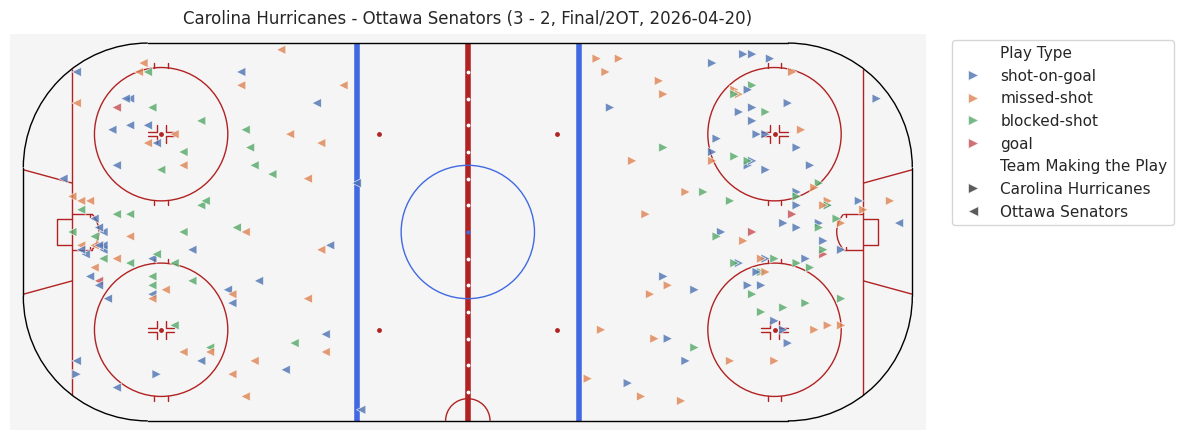

In [65]:
from rink import plot_rink

game_shots = all_shots[all_shots['Game ID'] == idxmax].copy()

# Создаём координаты для графика
game_shots['X'] = game_shots['X Coordinate on the Ice Rink']
game_shots['Y'] = game_shots['Y Coordinate on the Ice Rink']

# В нечётных периодах меняем знаки координат
odd = game_shots['Period'] % 2 == 1

game_shots.loc[odd, 'X'] *= -1
game_shots.loc[odd, 'Y'] *= -1

# Определяем хозяев и гостей
home = game_shots['Home Team'].iloc[0]
away = game_shots['Away Team'].iloc[0]

# Строим хоккейную площадку и наносим броски
plt.figure(figsize=(12, 8))
plot_rink()

sns.scatterplot(
    data=game_shots, x='X', y='Y',
    hue='Play Type', style='Team Making the Play',
    markers={home: '>', away: '<'},
    s=45, alpha=0.8
)

plt.gca().set_aspect('equal')
plt.xlim(-103, 103)
plt.ylim(-45, 45)
plt.title(gameInfo(idxmax))
plt.axis('off')
plt.legend(loc='upper left', bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

#### 16  Cписок из десяти лучших игроков

In [66]:
# Выбираем события, в которых был забит гол
goals = events[events['Play Type'] == 'goal']

# Считаем количество голов каждого игрока
goal_counts = goals['Player in the Event #1'].value_counts()

# Результат
goal_counts.to_frame('Goals').head(10)

,Goals
Player in the Event #1,
Brett Howden,14
Pavel Dorofeyev,12
Logan Stankoven,11
Mitch Marner,10
Jordan Staal,8
Nikolaj Ehlers,8
Nathan MacKinnon,7
Taylor Hall,7
Mark Stone,7


#### 17 Больше всего голевых передач

In [67]:
# Объединяем игроков, сделавших голевые передачи
assists = pd.concat([
    goals['Player in the Event #2'],
    goals['Player in the Event #3']
])

# Считаем количество передач каждого игрока
assist_counts = assists.value_counts()

# Выводим результат
assist_counts.to_frame('Assists').head(10)

,Assists
Jack Eichel,20
Mitch Marner,19
Jackson Blake,13
Lane Hutson,13
Taylor Hall,12
Martin Necas,12
Nick Suzuki,12
Shea Theodore,12
Quinn Hughes,11
Kirill Kaprizov,11


#### 18 Максимум очков по системе гол+пас

In [68]:
# Складываем голы и передачи
points = goal_counts.add(assist_counts, fill_value=0).sort_values(ascending=False)

# Выводим результат
points.astype(int).to_frame('Points').head(10)

,Points
Mitch Marner,29
Jack Eichel,22
Jackson Blake,20
Taylor Hall,19
Shea Theodore,18
Nikolaj Ehlers,18
Brett Howden,18
Nick Suzuki,16
Lane Hutson,16
Pavel Dorofeyev,16


#### 19 Десять игроков по средним броскам в створ за матч

In [69]:
# Считаем количество точных бросков каждого игрока
shot_counts = shots[shots['Shot'] == 'On goal']['Player in the Event #1'].value_counts()

# Выбираем столбцы с игроками на льду
player_columns = [col for col in events.columns if 'Player on the Ice #' in col]

# Собираем всех игроков в один столбец
players = events.set_index('Game ID')[player_columns].stack()

players = players.reset_index(name='Player')

# Считаем количество сыгранных матчей каждого игрока
games_played = players.groupby('Player')['Game ID'].nunique()

# Считаем среднее количество бросков за матч
avg_shots = (shot_counts / games_played).sort_values(ascending=False)

# Выводим топ-10
avg_shots.to_frame('Shots per Game').head(10).round(3)

,Shots per Game
Jason Robertson,5.000
Dylan Guenther,4.500
Nikita Kucherov,4.429
Matt Boldy,4.364
Quinton Byfield,4.250
Joel Eriksson Ek,4.000
Darren Raddysh,4.000
Alex Laferriere,3.750
David Pastrnak,3.667
Nathan MacKinnon,3.615


#### 20 Топ 10 по средним силовым приемам за матч

In [70]:
# Выбираем события
hits = events[events['Play Type'] == 'hit']

# Считаем количество силовых приёмов каждого игрока
hit_counts = hits['Player in the Event #1'].value_counts()

# Считаем среднее количество силовых приёмов за матч
avg_hits = (hit_counts / games_played).sort_values(ascending=False)

# Выводим топ-10 игроков
avg_hits.to_frame('Hits per Game').head(10).round(3)

,Hits per Game
Lawson Crouse,6.333
Alexander Petrovic,6.000
Alex Turcotte,6.000
Yakov Trenin,5.667
Dylan Cozens,5.500
Vasily Podkolzin,5.333
Marcus Foligno,5.000
Carl Grundstrom,5.000
Ivan Barbashev,5.000
Owen Tippett,4.833


#### 21 Список вратарей хотя бы раз не пропустили

In [71]:
# Выбираем столбцы с вратарями
goalie_cols = ["Away Team's Goalie", "Home Team's Goalie"]

# Собираем всех вратарей, участвовавших в каждом матче
goalies = events.set_index('Game ID')[goalie_cols].stack().reset_index(name='Goalie')
goalies = goalies[['Game ID', 'Goalie']].drop_duplicates()

# Для каждого гола определяем вратаря пропустившей команды
goal_events = goals.copy()

goal_events['Goalie'] = np.where(
    goal_events['Team Making the Play'] == goal_events['Home Team'],
    goal_events["Away Team's Goalie"],
    goal_events["Home Team's Goalie"]
)

# Считаем пропущенные голы каждого вратаря в каждом матче
goals_against = goal_events.groupby(['Game ID', 'Goalie']).size().reset_index(name='Goals Against')

# Добавляем количество пропущенных голов ко всем вратарям
goalie_stats = goalies.merge(goals_against, on=['Game ID', 'Goalie'], how='left')
goalie_stats['Goals Against'] = goalie_stats['Goals Against'].fillna(0)

# Выбираем вратарей, которые хотя бы в одном матче не пропустили голов
zero_goalies = goalie_stats[goalie_stats['Goals Against'] == 0]

# Выводим уникальные имена вратарей
zero_goalies['Goalie'].drop_duplicates().sort_values().to_frame('Goalie').reset_index(drop=True)

,Goalie
0,Andrei Vasilevskiy
1,Arturs Silovs
2,Brandon Bussi
3,Dan Vladar
4,Frederik Andersen
5,Jakub Dobes
6,Joonas Korpisalo
7,Scott Wedgewood


В плей-офф нашлось 8 вратарей, которые хотя бы в одном матче не пропустили ни одной шайбы.

#### 22 Доп. вопрос

**Какая доля матчей плей-офф закончилась победой хозяев и наблюдается ли преимущество своей площадки?**

In [72]:
# Считаем количество побед хозяев и гостей
home_wins = (games['Home Score'] > games['Away Score']).sum()
away_wins = (games['Away Score'] > games['Home Score']).sum()

# Считаем долю побед хозяев
home_share = home_wins / len(games) * 100

# Выводим результаты
print(f'Победы хозяев {home_wins}')
print(f'Победы гостей {away_wins}')
print(f'Доля побед хозяев {round(home_share, 1)}%')

Победы хозяев 39
Победы гостей 43
Доля побед хозяев 47.6%


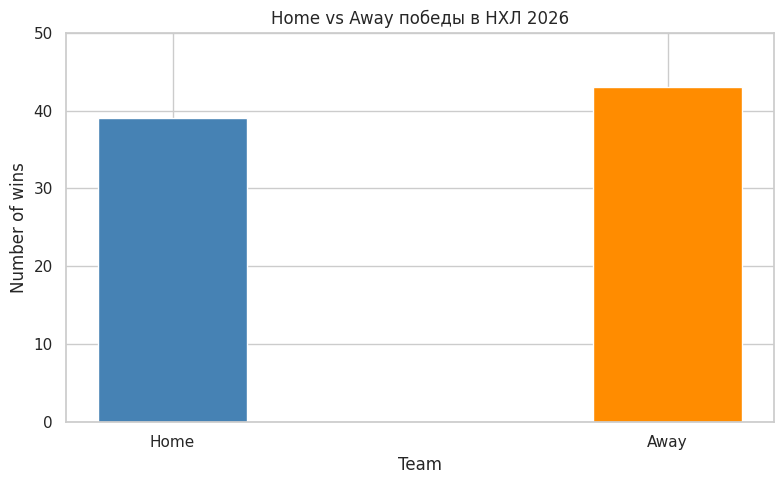

In [73]:
plt.figure(figsize=(8, 5))

plt.bar(
    ['Home', 'Away'],
    [home_wins, away_wins],
    color=['steelblue', 'darkorange'],
    width=0.3
)

plt.xlabel('Team')
plt.ylabel('Number of wins')
plt.title('Home vs Away победы в НХЛ 2026')
plt.ylim(0, 50)
plt.tight_layout()
plt.show()

В плей-офф НХЛ 2026 года хозяева выиграли 39 из 82 матчей (47,6%), а гости 43 матча (52,4%). Таким образом, команды, игравшие в гостях, побеждали немного чаще. Однако разница составляет всего 4 матча, поэтому нельзя утверждать, что игра в гостях даёт преимущество.